# Average receptive-field mapping on 2P data

This notebook walks through converting a session to the ONE format, mapping average receptive fields, and plotting the results.

In [ ]:
from pathlib import Path

import numpy as np

from OneConverter import OneSessionConverter, explain_dataset
from one.api import One

from mapAverageRF import map_average_rf
from single_session_plots import plot_session
from grouped_session_plots import plot_group




# Temporary bloat to turn off warnings 
import logging
import warnings
from one.alf.exceptions import ALFWarning

# The index stores no file hashes, so every load logs "local md5 mismatch"; the files are fine
logging.getLogger("one").setLevel(logging.ERROR)
# Our sessions have no default revision, so every load warns about it; ONE loads the latest one
warnings.filterwarnings("ignore", category=ALFWarning)


## 1. Converting a session (OneConverter)

`OneSessionConverter` finds a session's raw and Suite2p files and converts them to ONE files in `one_root`.

Give it the modality, subject, date, session number and three folders:
- `raw_data_root`: raw acquisition data
- `processed_data_root`: Suite2p output
- `one_root`: where converted sessions are written

In [2]:
session_converter = OneSessionConverter(
    "2P",        # modality
    "NM023",     # subject
    "20260428",  # date
    1,           # session number
    raw_data_root="//10.233.25.135/FANCiNAS1/Data",
    processed_data_root="//10.233.25.135/FANCiNAS1/Processed",
    one_root="./ExampleRoot/",
)

MpciExporter(batch_list=[WindowsPath('20260428/1')], selected_batch=WindowsPath('20260428/1'), mid_frame_times=False)
SparseNoiseExporter(sparse_noise_shape=(7, 27), stimulus_values={'gray': -128, 'black': -1, 'white': 0}, stimulus_edges_deg=(-135.0, 135.0, -40.0, 40.0))
WheelExporter(encoder_counts_per_revolution=4096)


### Exporters

An exporter handles one type of acquisition, so far we have three implemented: 2P imaging (`MpciExporter`), sparse noise stimulus (`SparseNoiseExporter`) and wheel (`WheelExporter`). OneSessionConverter automatically detects the relevant acquisitions and exporters for your specified session

In [3]:
# print detected exporters and their default settings
for exporter in session_converter.exporters:
    print(exporter)

MpciExporter(batch_list=[WindowsPath('20260428/1')], selected_batch=WindowsPath('20260428/1'), mid_frame_times=False)
SparseNoiseExporter(sparse_noise_shape=(7, 27), stimulus_values={'gray': -128, 'black': -1, 'white': 0}, stimulus_edges_deg=(-135.0, 135.0, -40.0, 40.0))
WheelExporter(encoder_counts_per_revolution=4096)


Change a setting before exporting:

In [4]:
session_converter.exporters.SparseNoiseExporter.sparse_noise_shape = (7, 27)                       # (rows, columns) of the stimulus grid
session_converter.exporters.SparseNoiseExporter.stimulus_edges_deg = (-135.0, 135.0, -40.0, 40.0)  # (left, right, bottom, top) in degrees



### Exporter settings

A Suite2p run can combine several sessions. `MpciExporter` lists in `batch_list` every run that contains this session, and exports `selected_batch`. From that run, it keeps only this session's frames.

| Exporter | Setting | Default | Meaning |
|---|---|---|---|
| `MpciExporter` | `batch_list` | found automatically | Suite2p runs found for this session |
| | `selected_batch` | first of `batch_list` | Suite2p run to export |
| | `mid_frame_times` | `False` | Frame time = middle of the FOV's share of the DI3 onset-to-offset window, not its start |
| `SparseNoiseExporter` | `sparse_noise_shape` | `(7, 27)` | Stimulus grid size: (rows, columns) |
| | `stimulus_edges_deg` | `(-135, 135, -40, 40)` | Screen edges in degrees: (left, right, bottom, top) |
| | `stimulus_values` | `{'gray': -128, 'black': -1, 'white': 0}` | Value of each square colour in `SparseNoise_Log.bin` |
| `WheelExporter` | `encoder_counts_per_revolution` | `4096` | Wheel encoder counts per full turn |

### Export

`export()` writes the files. If the session was already exported, nothing is written. Use `force_export=True` to export again and overwrite it, e.g. after changing a setting.

In [5]:
session_converter.export()
# session_converter.export(force_export=True)

[WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.ROIActivityDeconvolved.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.ROIActivityF.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.ROINeuropilActivityF.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.badFrames.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.times.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpciMeanImage.images.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpciROIs.cellClassifier.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpciROIs.masks.sparse_npz'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpciROIs.mpciROITypes.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpciROIs.stackPos.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/FOV_01/mpci.ROIActivityDeconvolved.npy'),
 WindowsPath('ExampleRoot/NM023/2026-04-28/001/alf/F

### Where the files go

```
ExampleRoot/                     one_root
├── NM023/2026-04-28/001/        one session: subject/date/number
│   ├── alf/                     stimulus and wheel
│   │   ├── FOV_00/              imaging data of each FOV
│   │   └── FOV_01/
│   └── raw_passive_data/        raw stimulus movie
├── sessions.pqt, datasets.pqt   list of all sessions and files, the index read by ONE
└── dataset_types.json           description of each file
```

More on this in the ONE section.

### What is in a file?

`explain_dataset` prints a file's description: its content, units and shape. It needs a `One` object (see the ONE section below) and a file name.

In [6]:
one = One("./ExampleRoot/", mode="local")

explain_dataset(one, "mpci.ROIActivityF.npy")

Mean activity of all pixels in each ROI.

Dataset: mpci.ROIActivityF.npy
Units: photodetector output units
Type: float32
Dimensions: [nFrames, nROIs]
Format: npy


## 2. Finding and loading data (ONE)

After converting the relevant session(s) we will use `One` to load the standardized data. The `One` object in python is basically an index of the files across exported sessions under `./ExampleRoot/`. 

In [ ]:
# This loads the index. We will use this one variable to navigate our sessions and files
one = One("./ExampleRoot/", mode="local")
# You can also get the path from the converter
one = One(session_converter.one_root, mode="local")



### How files are organised (ALF)

ONE follows IBL's ALF file convention. Every file path has the form

```
<one_root>/<subject>/<date>/<number>/<collection>/#<revision>#/<object>.<attribute>.<extension>
ExampleRoot/NM023/2026-04-28/001/alf/FOV_00/mpci.times.npy
```

| Part | Meaning | Example |
|---|---|---|
| Session | one folder per experiment: subject/date/number | `NM023/2026-04-28/001` |
| Collection | sub-folder grouping files; needed when the same files exist more than once | `alf/FOV_00`, `alf/FOV_01`: the same files for each FOV |
| Dataset | one file: `object.attribute.extension` | `mpci.times.npy` |
| Object | the datasets sharing an object name in a collection. They all have the same number of rows, so together they form a table whose columns are the attributes | `mpci`: `mpci.times`, `mpci.ROIActivityF`, `mpci.badFrames`... one row per imaging frame |
| Namespace | optional `_name_` prefix for data that are not an IBL standard or belong to one setup | `_ibl_wheel.position.npy`, `_iblrig_RFMapStim.raw.bin` |
| Revision | optional `#name#` sub-folder of a collection holding one version of its datasets, so earlier results are never overwritten. ONE loads the latest by default; pass e.g. `revision="2026-10-27"` to get that one (if it does not exist, the closest earlier one; revisions are sorted alphabetically) | `alf/FOV_00/rf_deconv/#2026-10-27#/`; a second run that day goes to `#2026-10-27a#`. This example is taken from rf mapping below |

### One clock for every file

Files whose attribute is `times` (or ends with it) or `timestamps` hold times in seconds from the start of the session, and all files of a session share that start. Imaging frames, wheel and stimulus can therefore be compared directly, with no alignment.

In our sessions, time 0 is the first timestamp in the raw `timestamped_digital.csv`.

### The session path

Every ONE function below takes the session folder: `one_root/subject/date/number`.

In [8]:
session_path = Path("./ExampleRoot/NM023/2026-04-28/001/")
# You can also get the path from the converter
session_path = session_converter.session_path

print(session_path)

ExampleRoot\NM023\2026-04-28\001


### List collections, datasets and revisions

In [9]:
session_collections = one.list_collections(session_path) 

print("> all collections under", session_path, ":")
print(*session_collections, sep="\n")  

> all collections under ExampleRoot\NM023\2026-04-28\001 :
alf/FOV_00
alf/FOV_01
alf
raw_passive_data


In [10]:
session_datasets = one.list_datasets(session_path)

print("\n> all datasets under", session_path, ":")
print(*session_datasets, sep="\n")  



> all datasets under ExampleRoot\NM023\2026-04-28\001 :
alf/FOV_00/mpci.ROIActivityDeconvolved.npy
alf/FOV_00/mpci.ROIActivityF.npy
alf/FOV_00/mpci.ROINeuropilActivityF.npy
alf/FOV_00/mpci.badFrames.npy
alf/FOV_00/mpci.times.npy
alf/FOV_00/mpciMeanImage.images.npy
alf/FOV_00/mpciROIs.cellClassifier.npy
alf/FOV_00/mpciROIs.masks.sparse_npz
alf/FOV_00/mpciROIs.mpciROITypes.npy
alf/FOV_00/mpciROIs.stackPos.npy
alf/FOV_01/mpci.ROIActivityDeconvolved.npy
alf/FOV_01/mpci.ROIActivityF.npy
alf/FOV_01/mpci.ROINeuropilActivityF.npy
alf/FOV_01/mpci.badFrames.npy
alf/FOV_01/mpci.times.npy
alf/FOV_01/mpciMeanImage.images.npy
alf/FOV_01/mpciROIs.cellClassifier.npy
alf/FOV_01/mpciROIs.masks.sparse_npz
alf/FOV_01/mpciROIs.mpciROITypes.npy
alf/FOV_01/mpciROIs.stackPos.npy
alf/_ibl_passiveRFM.times.npy
alf/_ibl_sparseNoise.times.npy
alf/_ibl_sparseNoise.xy.npy
alf/_ibl_wheel.position.npy
alf/_ibl_wheel.timestamps.npy
alf/_ibl_wheel.velocity.npy
raw_passive_data/_iblrig_RFMapStim.raw.bin


In [11]:
alf_datasets = one.list_datasets(session_path, collection="alf")
FOV_00_datasets = one.list_datasets(session_path, collection="alf/FOV_00") # FOV_XX corresponds to planeX folder in s2p outputs

print("\n> datasets in", session_path / "alf", ":")
print(*alf_datasets, sep="\n")

print("\n> datasets in", session_path / "alf/FOV_00", ":")
print(*FOV_00_datasets, sep="\n")


> datasets in ExampleRoot\NM023\2026-04-28\001\alf :
alf/_ibl_passiveRFM.times.npy
alf/_ibl_sparseNoise.times.npy
alf/_ibl_sparseNoise.xy.npy
alf/_ibl_wheel.position.npy
alf/_ibl_wheel.timestamps.npy
alf/_ibl_wheel.velocity.npy

> datasets in ExampleRoot\NM023\2026-04-28\001\alf\FOV_00 :
alf/FOV_00/mpci.ROIActivityDeconvolved.npy
alf/FOV_00/mpci.ROIActivityF.npy
alf/FOV_00/mpci.ROINeuropilActivityF.npy
alf/FOV_00/mpci.badFrames.npy
alf/FOV_00/mpci.times.npy
alf/FOV_00/mpciMeanImage.images.npy
alf/FOV_00/mpciROIs.cellClassifier.npy
alf/FOV_00/mpciROIs.masks.sparse_npz
alf/FOV_00/mpciROIs.mpciROITypes.npy
alf/FOV_00/mpciROIs.stackPos.npy


In [ ]:
#one.list_revisions(session_path, collection="....") 
# # revisions are folder marked with ..\collection\#date#\...
# You would need revisions if you have multiple s2p runs (or any processing) on the same data with different results.
# Our current converter does not support s2p revisions, but the RF mapping in the next section does. We will see the example there

SyntaxError: invalid syntax (891201614.py, line 1)

In [ ]:
# paste filenames (with or without parent folders) to see documentation as needed
explain_dataset(one, "alf/_ibl_sparseNoise.xy.npy") 

Screen x/y coordinates of each non-gray sparse-noise stimulus square.

Dataset: _ibl_sparseNoise.xy.npy
Units: the public dataset-types spreadsheet leaves the unit unresolved; this
exporter follows the previous implementation and writes visual degrees
Type: float64
Dimensions: [nSparseNoise, 2]
Format: npy



### Load a dataset

`load_dataset` loads one file, here as a numpy array:

In [14]:
frame_times = one.load_dataset(session_path, "mpci.times.npy", collection="alf/FOV_00")
print(frame_times.shape, frame_times[:5]) 



(11205,) [0.       0.16096  0.32192  0.482912 0.643872]


### Load an object

`load_object` loads all datasets of an object into a dictionary keyed by attribute; `mpci["times"]` can also be written `mpci.times`:

In [ ]:
mpci = one.load_object(session_path, "mpci", collection="alf/FOV_00")
print(mpci.times.shape)
print(mpci.ROIActivityDeconvolved.shape)
print(mpci["ROINeuropilActivityF"].shape) # I would avoid using this dictionary notation. 


(11205,)
(11205, 2199)
(11205, 2199)


### Load a collection

`load_collection` loads every object of a collection, keyed by object name:

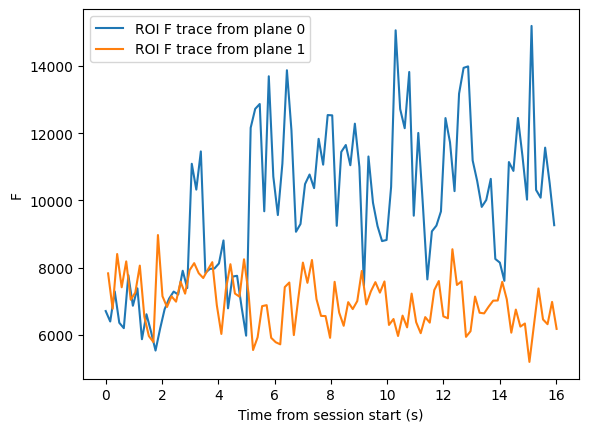

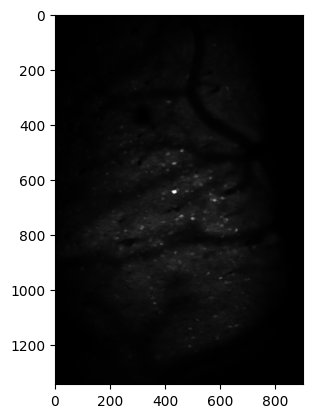

In [16]:
fov0 = one.load_collection(session_path, "alf/FOV_00") 
fov1 = one.load_collection(session_path, "alf/FOV_01")

#let's plot some F traces
import matplotlib.pyplot as plt
plt.plot(fov0.mpci.times[:100], fov0.mpci.ROIActivityF[:100,0], label="ROI F trace from plane 0")
plt.plot(fov1.mpci.times[:100], fov1.mpci.ROIActivityF[:100,0], label="ROI F trace from plane 1")
plt.xlabel("Time from session start (s)")
plt.ylabel("F")
plt.legend()
plt.show()

#plot mean Image
plt.imshow(fov0.mpciMeanImage["images"][:, :, 0, 0], cmap="gray")



### One clock: check

Imaging, wheel and stimulus times are all in seconds from the same session start, so they can be compared directly:

In [17]:
wheel = one.load_object(session_path, "wheel", collection="alf")
stimulus_times = one.load_dataset(session_path, "_ibl_passiveRFM.times.npy", collection="alf")

for name, times in [("imaging frames", mpci.times), ("wheel", wheel.timestamps), ("stimulus frames", stimulus_times)]:
    print(f"{name:16s} {times[0]:8.2f} s to {times[-1]:8.2f} s")


print("\nThe original time 0 is the first timestamp in timestamped_digital.csv:", session_converter.session_time_zero)

imaging frames       0.00 s to  1803.75 s
wheel                0.48 s to  1803.67 s
stimulus frames      2.00 s to  1799.83 s

The original time 0 is the first timestamp in timestamped_digital.csv: 436011.767552


## 3. Mapping receptive fields

### Settings

`map_average_rf` has many `settings`; all of them have default values documented inside the function, here are the relevant ones to pass:


**Required**

| Setting | Meaning |
|---|---|
| `sparse_noise_shape` | Stimulus grid (rows, columns). Same values as given to the converter. |
| `stimulus_edges_deg` | Screen edges in degrees (left, right, bottom, top). Same values as given to the converter. |
| `right_hemisphere_fovs` | FOVs imaged in the right hemisphere, e.g. `["FOV_01"]`; the others are treated as left. Their stimulus is mirrored, so positive azimuth is always contralateral. |

**Important**

| Setting | Default | Meaning |
|---|---|---|
| `rf_time_limits` | `(0.2, 1.0)` | Delays after each stimulus frame (s) in which the response is searched for. Must cover the response delay of your indicator and signal. |
| `signal` | `"traces"` | `"traces"`: neuropil-corrected, smoothed F. `"deconvolved"`: Suite2p spikes. |
| `n_shifts` | `500` | Shuffles for the p-values, which come in steps of 1/`n_shifts`. Use 500 for results. A few (e.g. 5) only for quick test runs: a neuron then passes p < 0.05 as soon as none of the 5 shuffles beats it. |

**Optional**

| Setting | Default | Meaning |
|---|---|---|
| `l1_enabled` | `False` | Add an L1 penalty to the fit. Much slower but may produce more good RFs. |
| `running_regressor` | `False` | Add running speed (wheel) as extra predictors;  |
| `azimuth_range_contra_deg` | `None` | Fit only part of the screen: (ipsilateral, contralateral) azimuth limits in degrees towards the FOV's contralateral side, 0 = midline, e.g. `(-10, 90)`. `None` = whole screen; `None` inside the pair = no limit on that side. |
| `elevation_range_deg` | `None` | Same for elevation: (lower, upper) in degrees, e.g. `(-20, 40)`. |

In [ ]:
settings = {
    # Required
    "sparse_noise_shape": (7, 27),                       # (rows, columns), as in the conversion
    "stimulus_edges_deg": (-135.0, 135.0, -40.0, 40.0),  # (left, right, bottom, top), as in the conversion
    "right_hemisphere_fovs": [],                         # e.g. ["FOV_01"]
    # Check for your data
    "rf_time_limits": (0.2, 1.0),                        # s
    "signal": "deconvolved",                             # "traces" or "deconvolved"
    "n_shifts": 5,                                     # e.g. 5 for a quick test run
    # Optional
    "l1_enabled": False,
    "running_regressor": False,
    "azimuth_range_contra_deg": None,                    # e.g. (-10, 90)
    "elevation_range_deg": None,                         # e.g. (-20, 40)
}

results_paths1 = map_average_rf(one, session_path, settings)

#let's turn on the running regressor and run it again 
settings["running_regressor"]=True
results_paths2 = map_average_rf(one, session_path, settings)


alf/FOV_00: 491 neurons (deconvolved, running regressor off, L1 off)
alf/FOV_00: 101 of 491 neurons have a significant RF
alf/FOV_00: 22 good RFs (peak/noise > 7.7)
alf/FOV_00: saved results to ExampleRoot\NM023\2026-04-28\001\alf\FOV_00\rf_deconv\#2026-10-27#
alf/FOV_01: 368 neurons (deconvolved, running regressor off, L1 off)
alf/FOV_01: 48 of 368 neurons have a significant RF
alf/FOV_01: 0 good RFs (peak/noise > 7.7)
alf/FOV_01: saved results to ExampleRoot\NM023\2026-04-28\001\alf\FOV_01\rf_deconv\#2026-10-27#
alf/FOV_00: 491 neurons (deconvolved, running regressor on, L1 off)
alf/FOV_00: 45 of 491 neurons have a significant RF
alf/FOV_00: 22 good RFs (peak/noise > 7.7)
alf/FOV_00: saved results to ExampleRoot\NM023\2026-04-28\001\alf\FOV_00\rf_deconv\#2026-10-27a#
alf/FOV_01: 368 neurons (deconvolved, running regressor on, L1 off)
alf/FOV_01: 8 of 368 neurons have a significant RF
alf/FOV_01: 0 good RFs (peak/noise > 7.7)
alf/FOV_01: saved results to ExampleRoot\NM023\2026-04-28\0

### Output

Results are saved inside the session, per FOV, in a sub-collection named after `signal`. Each run is a new revision:

```
alf/FOV_00/
├── rf_traces/                          signal = "traces"
│   └── #2026-10-27#/
└── rf_deconv/                          signal = "deconvolved"
    ├── #2026-10-27#/                   one run
    │   ├── _ss_averageRF.*.npy         one row per fitted neuron: maps, p-values, Gaussian fit, goodRF, ...
    │   └── _ss_averageRFRun.meta.json  settings, inputs and counts of the run
    └── #2026-10-27a#/                  a second run on the same day
```

Before fitting anything, `map_average_rf` compares the `settings` it was given with each saved revision. If one matches, the FOV is skipped and that revision is reused. You can force it to refit by adding `"force": True` to the settings.


In [19]:
print(*one.list_collections(session_path),sep="\n") # outputs saved under new collections
print()
print("Revisions:",one.list_revisions(session_path,collection="alf/FOV_01/rf_deconv")) # example use of list_revisions

one.list_datasets(session_path,collection="alf/FOV_01/rf_deconv",revision="2026-10-27a") # The outputs generated by map_average_rf

alf/FOV_00
alf/FOV_00/rf_deconv
alf/FOV_01/rf_deconv
alf
alf/FOV_01
raw_passive_data

Revisions: ['2026-10-27a', '2026-10-27']


['alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.bestSubfields.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.explainedVariance.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.explainedVarianceFullModel.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.gaussPars.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.goodRF.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.lambdas.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.maps.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.meta.json',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.mpciROIs.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.optimalDelays.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.pValues.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.peakToNoise.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.runLambdas.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_ss_averageRF.runningKernels.npy',
 'alf/FOV_01/rf_deconv/#2026-10-27a#/_

In [20]:
explain_dataset(one,'_ss_averageRF.pValues.npy') # explain_dataset also works on rf outputs

Significance of each RF: fraction of circular-shift refits whose stimulus explained variance is above the real one.

    Dataset: _ss_averageRF.pValues.npy
    Units: probability
    Type: float64
    Dimensions: [nNeurons]
    Format: npy

    Resolution is 1/n_shifts (meta.json settings); 0 means p < 1/n_shifts. NaN for neurons that were not fitted.


In [21]:
averageRF_with_running_regressor = one.load_object(session_path, "averageRF", collection="alf/FOV_00/rf_deconv")  # automatically loads latest revision ('2026-10-27a') 
averageRF_without_running_regressor = one.load_object(session_path, "averageRF", collection="alf/FOV_00/rf_deconv",revision='2026-10-27')  # load from a specified revision

print("FOV_00 deconv: p < 0.05 without running regressors =", (averageRF_without_running_regressor.pValues < 0.05).sum())
print("FOV_00 deconf: p < 0.05 with running regressors=   ", (averageRF_with_running_regressor.pValues < 0.05).sum())


FOV_00 deconv: p < 0.05 without running regressors = 205
FOV_00 deconf: p < 0.05 with running regressors=    115


In [ ]:
# Each revision stores its own rf mapping settings in this dataset:
explain_dataset(one,'_ss_averageRFRun.meta.json') # explain_dataset also works on rf outputs

### Plotting

- `plot_session` plots one run of one session: each FOV, then all FOVs pooled. Plots go to `<output_dir>/<subject>/<date>/<number>/FOV_XX/rf_<signal>/<revision>/` and `.../session/rf_<signal>/<revision>/`
- `plot_group` pools all FOVs of several sessions. Plots go to `<output_dir>/<group_name>/`, with `group_runs.txt` listing the runs used.

Plotting function can overwrite existing plot files

In [23]:
plot_settings = {
    "signal": "latest",                # "traces", "deconvolved", or "latest" (the session's most recent run)
    "revision": "latest",              # or a revision, e.g. "2026-10-27"
    "output_dir": "./ExamplePlots/",   # required, keep it outside of one_root
    "azimuth_range_contra_deg": None,  # zoom, e.g. (-10, 90); None = whole screen
    # Plots per FOV and for the pooled session
    "gaussian_coverage": True,         # summed Gaussian RFs over the visual field
    "rf_size": True,                   # size of good RFs
    "explained_variance": True,        # EV, significant vs. the rest
    "roi_overlays": True,              # ROIs on the mean image
    "rf_roi_overlay": True,            # neurons coloured by RF centre on the mean image
    # Plots per FOV only
    "rf_maps": True,                   # one RF map per neuron
    "n_rf_maps_good": 10,              # best good RFs to plot; None = all
    "n_rf_maps_significant": 10,       # best significant but not good RFs to plot; None = all
    "predicted_vs_actual": True,       # traces vs. model prediction
    "peak_time_courses": True,         # RF time course at the RF centre
}

plot_folders = plot_session(one, session_path, plot_settings)

alf/FOV_00: plotting alf/FOV_00/rf_deconv/#2026-10-27a# (45 significant, 22 good RFs)
alf/FOV_01: plotting alf/FOV_01/rf_deconv/#2026-10-27a# (8 significant, 0 good RFs)
session: plotting FOV_00, FOV_01 -> ExamplePlots\NM023\2026-04-28\001\session\rf_deconv\2026-10-27a


In [24]:
group_settings = {
    "group_name": "exampleGroup",      # plots go to <output_dir>/<group_name>/
    "fov_runs": [                      # subject/date/number/alf/FOV_XX/<rf_traces|rf_deconv>[/#revision#]; no revision = latest
        "NM023/2026-04-28/001/alf/FOV_00/rf_deconv/#2026-10-27#",  # without running regressor
        "NM023/2026-04-28/001/alf/FOV_01/rf_deconv/",              # with running regressor. 
    ],
    "output_dir": "./ExamplePlots/",   # required
    "azimuth_range_contra_deg": None,  # zoom, e.g. (-10, 90); None = whole screen
    # Plots
    "rf_centres": True,                # RF centres over the visual field
    "gaussian_coverage": True,         # summed Gaussian RFs: good vs. all significant
    "explained_variance": True,        # EV per session and their mean; rebuilds the traces (slow)
    "rf_size": True,                   # good-RF size per session and their mean
}

group_folder = plot_group(one, group_settings) 



exampleGroup: plotting
  NM023/2026-04-28/001 FOV_00 deconvolved #2026-10-27# left hemisphere: 101 significant, 22 good RFs
  NM023/2026-04-28/001 FOV_01 deconvolved #2026-10-27a# left hemisphere: 8 significant, 0 good RFs
-> ExamplePlots\exampleGroup
NM023/2026-04-28/001: rebuilding the traces for the explained variance


Note that our plot_group example uses two FOVs from the same session, so we are not really grouping sessions in the above example.
So let's do another session and recap from the beginning: NM034\2026-05-06\1



In [ ]:
# initialize converter 
session_converter_nm34 = OneSessionConverter(
    "2P",        # modality
    "NM034",     # subject
    "20260506",  # date
    1,           # session number
    raw_data_root="//10.233.25.135/FANCiNAS1/Data",
    processed_data_root="//10.233.25.135/FANCiNAS1/Processed",
    one_root="./ExampleRoot/",
)  

# Check and adjust exporter settings 
session_converter_nm34.exporters # (no need to change anything. Default exporter values work in all current sparse noise sessions)

# run the export
session_converter_nm34.export()

# load the one index so it can see the new session
one = One(session_converter_nm34.one_root, mode="local") # or reload using one.load_cache()

# run the RF mapper
session_path_nm34 = session_converter_nm34.session_path
settings_nm34 = {
    "sparse_noise_shape": (7, 27),                       
    "stimulus_edges_deg": (-135.0, 135.0, -40.0, 40.0),  
    "right_hemisphere_fovs": ["FOV_01"],            # not sure if this FOV is actually right hemisphere
    "signal": "traces",                             # let's use traces for this session instead
    "n_shifts": 5,                                  
}
result_paths= map_average_rf(one, session_path_nm34, settings_nm34)


# make plots
plot_settings_nm34 = {"output_dir":"./ExamplePlots/"} 
plot_session(one, session_path_nm34, plot_settings_nm34)


group_settings_nm34 = {
    "group_name": "twoSessionGroup",      
    "fov_runs": [                      
        "NM023/2026-04-28/001/alf/FOV_00/rf_deconv/#2026-10-27#",  # without running regressor
        "NM023/2026-04-28/001/alf/FOV_01/rf_deconv/",              # with running regressor. 
        "NM034/2026-05-06/001/alf/FOV_00/rf_traces",
        "NM034/2026-05-06/001/alf/FOV_01/rf_traces"
    ],
    "output_dir": "./ExamplePlots/"
}

plot_group(one, group_settings_nm34) 


MpciExporter(batch_list=[WindowsPath('20260506/1')], selected_batch=WindowsPath('20260506/1'), mid_frame_times=False)
SparseNoiseExporter(sparse_noise_shape=(7, 27), stimulus_values={'gray': -128, 'black': -1, 'white': 0}, stimulus_edges_deg=(-135.0, 135.0, -40.0, 40.0))
WheelExporter(encoder_counts_per_revolution=4096)
alf/FOV_00: 996 neurons (traces, running regressor off, L1 off)
alf/FOV_00: 201 of 996 neurons have a significant RF
alf/FOV_00: 0 good RFs (peak/noise > 7.7)
alf/FOV_00: saved results to ExampleRoot\NM034\2026-05-06\001\alf\FOV_00\rf_traces\#2026-10-27#
alf/FOV_01: 1798 neurons (traces, running regressor off, L1 off)
alf/FOV_01: 398 of 1798 neurons have a significant RF
alf/FOV_01: 0 good RFs (peak/noise > 7.7)
alf/FOV_01: saved results to ExampleRoot\NM034\2026-05-06\001\alf\FOV_01\rf_traces\#2026-10-27#
alf/FOV_00: plotting alf/FOV_00/rf_traces/#2026-10-27# (201 significant, 0 good RFs)
alf/FOV_01: plotting alf/FOV_01/rf_traces/#2026-10-27# (398 significant, 0 good R

WindowsPath('ExamplePlots/twoSessionGroup')